In [28]:
import oqupy
import numpy as np
import matplotlib.pyplot as plt
from qutip import partial_transpose, Qobj

In [53]:
sigma_x = oqupy.operators.sigma("x")
sigma_y = oqupy.operators.sigma("y")
sigma_z = oqupy.operators.sigma("z")
up_density_matrix = oqupy.operators.spin_dm("z+")
down_density_matrix = oqupy.operators.spin_dm("z-")

def log_neg(rho):
	rho_tr_A = partial_transpose(Qobj(rho, dims=[[2, 2], [2, 2]]), [1, 0]).full()
	rho_tr_A_norm = np.linalg.norm(rho_tr_A, 'nuc')
	return np.log2(rho_tr_A_norm)

In [ ]:
Omega = 10.
omega_cutoff = 15.
alpha = 1.5

n = 3
a = oqupy.operators.destroy(n)
adag = oqupy.operators.create(n)

system = oqupy.System(Omega * np.kron(adag @ a, adag @ a))
correlations = oqupy.PowerLawSD(alpha=0.5 * alpha,
                                zeta=1.,
                                cutoff=omega_cutoff,
                                cutoff_type='exponential',
                                temperature=0.)
bath = oqupy.Bath(np.kron(np.identity(n), a + adag), correlations)
tempo_parameters = oqupy.TempoParameters(dt=0.1, tcut=1., epsrel=1e-5)

r = 4.
lmbda = np.tanh(r)
state = np.zeros(n ** 2)
for i in range(n):
	s = np.zeros(n)
	s[i] = lmbda ** i
	state += np.kron(s, s)
state *= np.sqrt(1 - lmbda ** 2)
rho = np.outer(state, state)
rho /= np.trace(rho)

dynamics = oqupy.tempo_compute(system=system,
                               bath=bath,
                               initial_state=rho,
                               start_time=0.,
                               end_time=5.,
                               parameters=tempo_parameters,
                               unique=False)

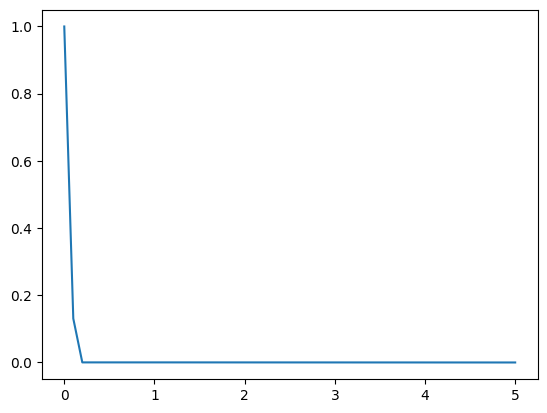

In [59]:
log_neg_list = np.array([log_neg(rho) for rho in dynamics.states])

plt.plot(np.arange(0, 5.1, 0.1), log_neg_list)